In [1]:
using LinearAlgebra
using Plots
using Printf
using LaTeXStrings

using Distributed
BLAS.set_num_threads(1)
addprocs(7, enable_threaded_blas=false);

In [2]:
gr();
# pyplot();
# plotlyjs();

In [3]:
@everywhere push!(LOAD_PATH, pwd())
@everywhere using Revise

In [4]:
using RMProblems  # Load on a single node first in case recompilation is needed
using RMSolver    # Load on a single node first in case recompilation is needed
@everywhere workers() using RMProblems
@everywhere workers() using RMSolver

┌ Info: Precompiling RMSolver [top-level]
└ @ Base loading.jl:1278


In [5]:
N_full = 900
N = 30

τ = 0.5

# σabs = 0.95
# θ = pi / 6
# w = 0.3

# σ = θ == 0.0 ? σabs : σabs * exp(im * θ)

# problem_full = example_problems[5](N=N_full, σ=σ, w=w, τ=τ)
# problem = example_problems[5](N=N, σ=σ, w=w, τ=τ)

σ = 1.0
w = 1.25
problem_full = example_problems[7](N=N_full, w=w, τ=τ)
problem = example_problems[7](N=N, w=w, τ=τ)

# problem.T .= repeat(sqrt.([0.7; 0.5; 0.3]), div(N, 3))

problem.M

30×30 SparseArrays.SparseMatrixCSC{Complex{Float64},Int64} with 29 stored entries:
  [1 ,  2]  =  1.25+0.0im
  [2 ,  3]  =  1.25+0.0im
  [3 ,  4]  =  1.25+0.0im
  [4 ,  5]  =  1.25+0.0im
  [5 ,  6]  =  1.25+0.0im
  [6 ,  7]  =  1.25+0.0im
  [7 ,  8]  =  1.25+0.0im
  [8 ,  9]  =  1.25+0.0im
  [9 , 10]  =  1.25+0.0im
  [10, 11]  =  1.25+0.0im
  [11, 12]  =  1.25+0.0im
  [12, 13]  =  1.25+0.0im
  ⋮
  [17, 18]  =  1.25+0.0im
  [18, 19]  =  1.25+0.0im
  [19, 20]  =  1.25+0.0im
  [20, 21]  =  1.25+0.0im
  [21, 22]  =  1.25+0.0im
  [22, 23]  =  1.25+0.0im
  [23, 24]  =  1.25+0.0im
  [24, 25]  =  1.25+0.0im
  [25, 26]  =  1.25+0.0im
  [26, 27]  =  1.25+0.0im
  [27, 28]  =  1.25+0.0im
  [28, 29]  =  1.25+0.0im
  [29, 30]  =  1.25+0.0im

In [6]:
using RMUtils

Mevs = unique(
    eigvals(Array(problem.M))
)

Jr = (1 / sqrt(N_full)) * rand([-1.0; 1.0], (N_full, N_full))
Jr = partially_hermitize(Jr, τ)
LJrR = problem_full.L * Jr * problem_full.R
Ar = problem_full.M + LJrR

Arevs = eigvals(Ar)
Jrevs = eigvals(Jr);

Jc = (1 / sqrt(2N_full)) * (randn(N_full, N_full) + im * randn(N_full, N_full))
Jc = partially_hermitize(Jc, τ)
LJcR = problem_full.L * Jc * problem_full.R
Ac = problem_full.M + LJcR

Acevs = eigvals(Ac)
Jcevs = eigvals(Jc);

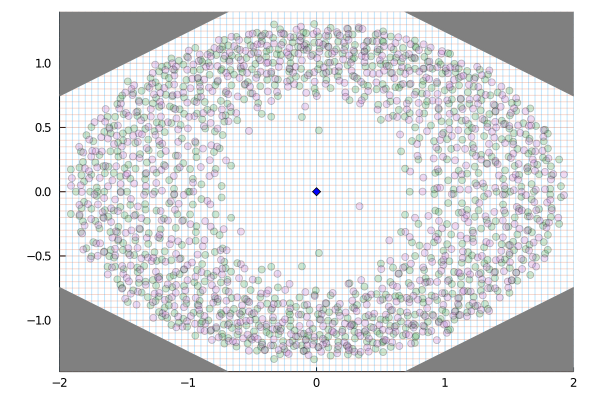

In [7]:
# xs = -1.5:0.05:2.0
# ys = -1.5:0.05:1.5
xs = -2.0:0.05:2.0
ys = -1.4:0.05:1.4

p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
scatter!(p, real(Arevs), imag(Arevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Acevs), imag(Acevs), alpha=0.25, aspect_ratio=:equal, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

function mask_outside_region!(p, bounds, ylims)
    for b in bounds
        if b.second === :L
            fr = ylims[1]
        elseif b.second === :U
            fr = ylims[end]
        else
            fr = nothing
        end
        plot!(p, b.first, lw=2, color=:gray, fillrange=fr, label="")
    end
    return p
end

bounds = Dict(
#     (x -> (2.8 / 5.0) * (x - 1.8)) => :L,
#     (x -> -(2.2 / 5.0) * (x - 3.4)) => :U,
#     (x -> (2.9 / 5.0) * (x + 2.6)) => :U,
    (x -> (2.5 / 5.0) * (x - 3.5)) => :L,
    (x -> -(2.5 / 5.0) * (x + 3.5)) => :L,
    (x -> -(2.5 / 5.0) * (x - 3.5)) => :U,
    (x -> (2.5 / 5.0) * (x + 3.5)) => :U,
)
mask_outside_region!(p, bounds, ys)

In [8]:
rbase = 3.0 / 2.0
start = 18
stop = -18

solve_gsq, solve_k = rm_solvers(
    problem=problem, rbase=rbase, start=start, stop=stop
);

In [9]:
z = -1.45 + 0.50im

solution = solve_gsq(z, debug=true);
#solution = solve_k(z, debug=true);

  z = -1.450 + i 0.500
-------------------------------------------------------
   γ^2        δ^2               q                k
-------------------------------------------------------
 1.48e+03   1.48e+03  -6.91e-04 + i-2.38e-04   6.75e-04
 9.85e+02   9.85e+02  -1.03e-03 + i-3.57e-04   1.01e-03
 6.57e+02   6.57e+02  -1.55e-03 + i-5.34e-04   1.51e-03
 4.38e+02   4.38e+02  -2.31e-03 + i-7.99e-04   2.26e-03
 2.92e+02   2.92e+02  -3.44e-03 + i-1.19e-03   3.38e-03
 1.95e+02   1.95e+02  -5.12e-03 + i-1.77e-03   5.04e-03
 1.30e+02   1.30e+02  -7.57e-03 + i-2.63e-03   7.49e-03
 8.64e+01   8.65e+01  -1.11e-02 + i-3.88e-03   1.11e-02
 5.76e+01   5.77e+01  -1.62e-02 + i-5.67e-03   1.63e-02
 3.84e+01   3.84e+01  -2.33e-02 + i-8.21e-03   2.38e-02
 2.55e+01   2.56e+01  -3.29e-02 + i-1.17e-02   3.44e-02
 1.70e+01   1.71e+01  -4.54e-02 + i-1.64e-02   4.89e-02
 1.13e+01   1.14e+01  -6.12e-02 + i-2.24e-02   6.84e-02
 7.52e+00   7.59e+00  -7.99e-02 + i-2.99e-02   9.41e-02
 5.00e+00   5.06e+00  -1.01e-0

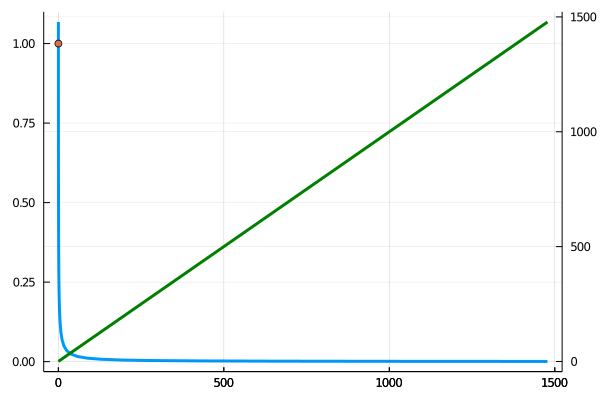

In [10]:
γsqs = [s.γsq for s in solution.trace]
δsqs = [s.δsq for s in solution.trace]
ks = [s.k for s in solution.trace]
plot(γsqs, ks, lw=3, label="")
scatter!([solution.γsq], [solution.k], label="")
plot!(twinx(), γsqs, δsqs, lw=3, color=:green, label="")

In [11]:
@everywhere solve_gsq, solve_k = rm_solvers(
    problem=$problem, rbase=$rbase, start=$start, stop=$stop,
)

function in_region(x, y, bounds)
    for b in bounds
        if ((b.second === :L) && (y < b.first(x)))
            return false
        end
        if ((b.second === :U) && (y > b.first(x)))
            return false
        end
    end
    return true
end

zs = [in_region(x, y, bounds) ? complex(x, y) : complex(NaN, NaN) for y in ys, x in xs];

In [12]:
solutions = pmap(solve_gsq, zs);

      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z =    NaN + i   NaN
      From worker 6:	  z = -2.000 + i-0.750
      From worker 4:	  z =    NaN + i   NaN
      From worker 2:	  z =    NaN + i   NaN
      From worker 4:	  z = -2.000 + i-0.700
      From worker 3:	  z =    NaN + i   NaN
      From worker 8:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 2:	  z = -2.000 + i-0.650
      From worker 3:	  z = -2.000 + i-0.600
      From worker 8:	  z = -2.000 + i-0.550
      From worker 5:	  z = -2.000 + i-0.500
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z = -2.000 + i-0.450
      From worker 6:	  z = -2.000 + i-0.400
      From worker 6:	  z = -2.000 + i-0.350
      From worker 6:	  z = -2.00

      From worker 6:	  z = -1.850 + i-0.600
      From worker 6:	  z = -1.850 + i-0.550
      From worker 6:	  z = -1.850 + i-0.500
      From worker 6:	  z = -1.850 + i-0.450
      From worker 6:	  z = -1.850 + i-0.400
      From worker 6:	  z = -1.850 + i-0.350
      From worker 6:	  z = -1.850 + i-0.300
      From worker 6:	  z = -1.850 + i-0.250
      From worker 6:	  z = -1.850 + i-0.200
      From worker 6:	  z = -1.850 + i-0.150
      From worker 6:	  z = -1.850 + i-0.100
      From worker 6:	  z = -1.850 + i-0.050
      From worker 6:	  z = -1.850 + i 0.000
      From worker 6:	  z = -1.850 + i 0.050
      From worker 6:	  z = -1.850 + i 0.100
      From worker 6:	  z = -1.850 + i 0.150
      From worker 6:	  z = -1.850 + i 0.200
      From worker 6:	  z = -1.850 + i 0.250
      From worker 6:	  z = -1.850 + i 0.300
      From worker 6:	  z = -1.850 + i 0.350
      From worker 6:	  z = -1.850 + i 0.400
      From worker 6:	  z = -1.850 + i 0.450
      From worker 6:	  z = -1.85

      From worker 5:	  z = -1.700 + i 0.350
      From worker 6:	  z = -1.700 + i 0.400
      From worker 2:	  z = -1.700 + i 0.450
      From worker 3:	  z = -1.700 + i 0.500
      From worker 8:	  z = -1.700 + i 0.550
      From worker 4:	  z = -1.700 + i 0.600
      From worker 5:	  z = -1.700 + i 0.650
      From worker 6:	  z = -1.700 + i 0.700
      From worker 3:	  z = -1.700 + i 0.750
      From worker 2:	  z = -1.700 + i 0.800
      From worker 8:	  z = -1.700 + i 0.850
      From worker 5:	  z = -1.700 + i 0.900
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    NaN + i   NaN
      From worker 4:	  z =    Na

      From worker 5:	  z = -1.500 + i-1.000
      From worker 4:	  z = -1.500 + i-0.950
      From worker 6:	  z = -1.500 + i-0.900
      From worker 3:	  z = -1.500 + i-0.850
      From worker 8:	  z = -1.500 + i-0.800
      From worker 7:	  z = -1.500 + i-0.750
      From worker 2:	  z = -1.500 + i-0.700
      From worker 5:	  z = -1.500 + i-0.650
      From worker 4:	  z = -1.500 + i-0.600
      From worker 6:	  z = -1.500 + i-0.550
      From worker 8:	  z = -1.500 + i-0.500
      From worker 3:	  z = -1.500 + i-0.450
      From worker 2:	  z = -1.500 + i-0.400
      From worker 5:	  z = -1.500 + i-0.350
      From worker 7:	  z = -1.500 + i-0.300
      From worker 8:	  z = -1.500 + i-0.250
      From worker 4:	  z = -1.500 + i-0.200
      From worker 6:	  z = -1.500 + i-0.150
      From worker 3:	  z = -1.500 + i-0.100
      From worker 8:	  z = -1.500 + i-0.050
      From worker 5:	  z = -1.500 + i 0.000
      From worker 7:	  z = -1.500 + i 0.050
      From worker 6:	  z = -1.50

      From worker 3:	  z = -1.350 + i 0.400
      From worker 6:	  z = -1.350 + i 0.450
      From worker 7:	  z = -1.350 + i 0.550
      From worker 8:	  z = -1.350 + i 0.500
      From worker 2:	  z = -1.350 + i 0.600
      From worker 5:	  z = -1.350 + i 0.650
      From worker 4:	  z = -1.350 + i 0.700
      From worker 7:	  z = -1.350 + i 0.750
      From worker 6:	  z = -1.350 + i 0.800
      From worker 3:	  z = -1.350 + i 0.850
      From worker 8:	  z = -1.350 + i 0.900
      From worker 2:	  z = -1.350 + i 0.950
      From worker 5:	  z = -1.350 + i 1.000
      From worker 4:	  z = -1.350 + i 1.050
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    NaN + i   NaN
      From worker 7:	  z =    Na

...

      From worker 6:	  z =  1.200 + i-0.650
      From worker 7:	  z =  1.200 + i-0.600
      From worker 4:	  z =  1.200 + i-0.550
      From worker 3:	  z =  1.200 + i-0.500
      From worker 2:	  z =  1.200 + i-0.450
      From worker 8:	  z =  1.200 + i-0.400
      From worker 5:	  z =  1.200 + i-0.350
      From worker 6:	  z =  1.200 + i-0.300
      From worker 4:	  z =  1.200 + i-0.250
      From worker 2:	  z =  1.200 + i-0.200
      From worker 3:	  z =  1.200 + i-0.150
      From worker 7:	  z =  1.200 + i-0.100
      From worker 8:	  z =  1.200 + i-0.050
      From worker 5:	  z =  1.200 + i 0.000
      From worker 6:	  z =  1.200 + i 0.050
      From worker 2:	  z =  1.200 + i 0.100
      From worker 4:	  z =  1.200 + i 0.150
      From worker 5:	  z =  1.200 + i 0.200
      From worker 3:	  z =  1.200 + i 0.250
      From worker 8:	  z =  1.200 + i 0.300
      From worker 7:	  z =  1.200 + i 0.350
      From worker 6:	  z =  1.200 + i 0.400
      From worker 2:	  z =  1.20

      From worker 6:	  z =  1.350 + i 0.650
      From worker 2:	  z =  1.350 + i 0.700
      From worker 5:	  z =  1.350 + i 0.750
      From worker 8:	  z =  1.350 + i 0.800
      From worker 3:	  z =  1.350 + i 0.850
      From worker 4:	  z =  1.350 + i 0.900
      From worker 7:	  z =  1.350 + i 0.950
      From worker 6:	  z =  1.350 + i 1.000
      From worker 2:	  z =  1.350 + i 1.050
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 8:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 8:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 8:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 8:	  z =    Na

      From worker 8:	  z =  1.550 + i-0.900
      From worker 6:	  z =  1.550 + i-0.850
      From worker 3:	  z =  1.550 + i-0.800
      From worker 5:	  z =  1.550 + i-0.750
      From worker 7:	  z =  1.550 + i-0.700
      From worker 2:	  z =  1.550 + i-0.650
      From worker 4:	  z =  1.550 + i-0.600
      From worker 6:	  z =  1.550 + i-0.550
      From worker 7:	  z =  1.550 + i-0.500
      From worker 8:	  z =  1.550 + i-0.450
      From worker 3:	  z =  1.550 + i-0.400
      From worker 5:	  z =  1.550 + i-0.350
      From worker 2:	  z =  1.550 + i-0.300
      From worker 4:	  z =  1.550 + i-0.250
      From worker 7:	  z =  1.550 + i-0.200
      From worker 6:	  z =  1.550 + i-0.150
      From worker 8:	  z =  1.550 + i-0.100
      From worker 3:	  z =  1.550 + i-0.050
      From worker 5:	  z =  1.550 + i 0.000
      From worker 2:	  z =  1.550 + i 0.050
      From worker 7:	  z =  1.550 + i 0.100
      From worker 4:	  z =  1.550 + i 0.150
      From worker 6:	  z =  1.55

      From worker 4:	  z =  1.700 + i 0.100
      From worker 3:	  z =  1.700 + i 0.150
      From worker 6:	  z =  1.700 + i 0.200
      From worker 5:	  z =  1.700 + i 0.250
      From worker 2:	  z =  1.700 + i 0.300
      From worker 7:	  z =  1.700 + i 0.350
      From worker 8:	  z =  1.700 + i 0.400
      From worker 4:	  z =  1.700 + i 0.450
      From worker 3:	  z =  1.700 + i 0.500
      From worker 6:	  z =  1.700 + i 0.550
      From worker 5:	  z =  1.700 + i 0.600
      From worker 2:	  z =  1.700 + i 0.700
      From worker 8:	  z =  1.700 + i 0.650
      From worker 7:	  z =  1.700 + i 0.750
      From worker 3:	  z =  1.700 + i 0.800
      From worker 4:	  z =  1.700 + i 0.850
      From worker 6:	  z =  1.700 + i 0.900
      From worker 2:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 2:	  z =    NaN + i   NaN
      From worker 5:	  z =    NaN + i   NaN
      From worker 2:	  z =    Na

      From worker 3:	  z =  1.900 + i-0.750
      From worker 2:	  z =  1.900 + i-0.700
      From worker 7:	  z =  1.900 + i-0.650
      From worker 8:	  z =  1.900 + i-0.600
      From worker 6:	  z =  1.900 + i-0.550
      From worker 5:	  z =  1.900 + i-0.500
      From worker 3:	  z =  1.900 + i-0.450
      From worker 4:	  z =  1.900 + i-0.400
      From worker 8:	  z =  1.900 + i-0.350
      From worker 7:	  z =  1.900 + i-0.300
      From worker 6:	  z =  1.900 + i-0.250
      From worker 2:	  z =  1.900 + i-0.200
      From worker 5:	  z =  1.900 + i-0.150
      From worker 3:	  z =  1.900 + i-0.100
      From worker 4:	  z =  1.900 + i-0.050
      From worker 6:	  z =  1.900 + i 0.000
      From worker 3:	  z =  1.900 + i 0.050
      From worker 8:	  z =  1.900 + i 0.100
      From worker 5:	  z =  1.900 + i 0.150
      From worker 2:	  z =  1.900 + i 0.200
      From worker 7:	  z =  1.900 + i 0.250
      From worker 3:	  z =  1.900 + i 0.300
      From worker 4:	  z =  1.90

In [13]:
qs = similar(zs)
gsqs = similar(zs, Float64)
ks = similar(zs, Float64)

function nanclamp(x::Real, lo, hi)
    if (x < lo) || (hi < x)
        return NaN
    end
    return x
end

function nanclamp(x::Complex, relo, rehi, imlo, imhi)
    return complex(nanclamp(real(x), relo, rehi), nanclamp(imag(x), imlo, imhi))
end

trunc = 2.0
for j in 1:length(xs)
    for i in 1:length(ys)
        @inbounds begin
            s = solutions[i, j]
            gsqs[i, j] = s.γsq
            qs[i, j] = nanclamp(s.q, -trunc, trunc, -trunc, trunc)
            ks[i, j] = nanclamp(s.k, 0.0, trunc)
        end
    end
end

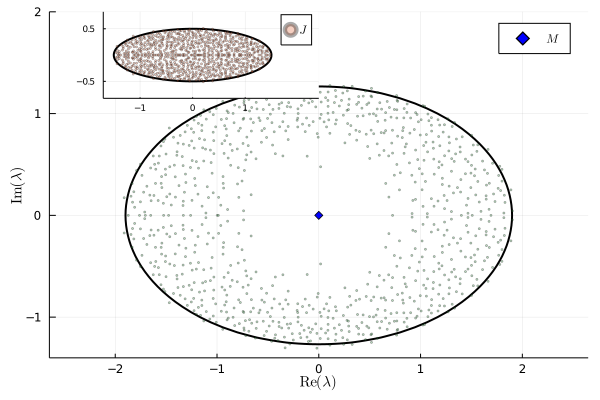

In [14]:
p = contour(
    xs,
    ys,
    gsqs,
    levels=[0.0],
    #ks,
    #levels=[1.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    #size=(270, 200),
    ylims=(ys[1], ys[end] + 0.6),
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.7, 2.4),
    xticks=[-1.0; 0.0; 1.0],
    yticks=[-0.5; 0.5],
    tickfontsize=6,
    inset_subplots=(1, bbox(0.1, 0.0, 0.4, 0.25)),
    subplot=2,
)

scatter!(
    p,
    real(Arevs),
    imag(Arevs),
    #real(Acevs),
    #imag(Acevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    #label=L"M + 0.95 J",
    label="",
    subplot=1,
)

scatter!(
    p,
    real(Jrevs),
    imag(Jrevs),
    #real(Jcevs),
    #imag(Jcevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

p

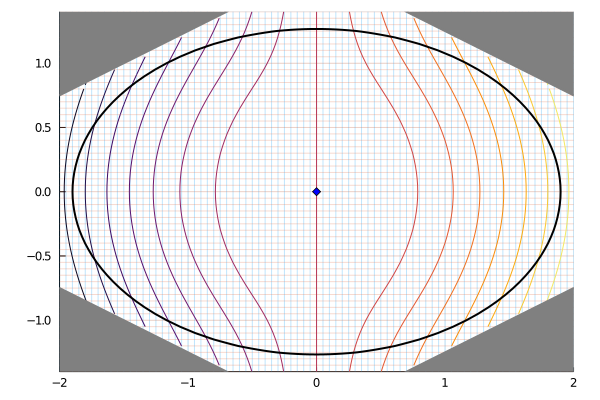

In [15]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, real(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

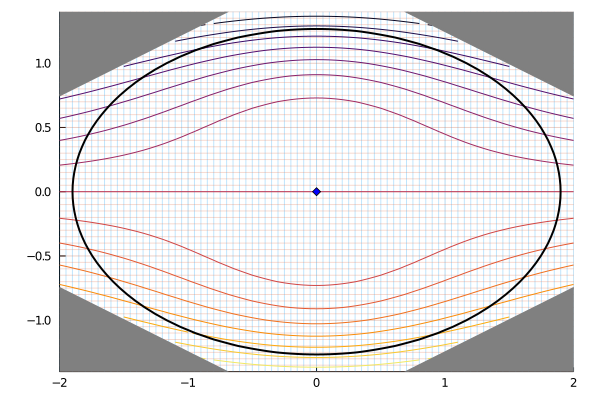

In [16]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, imag(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

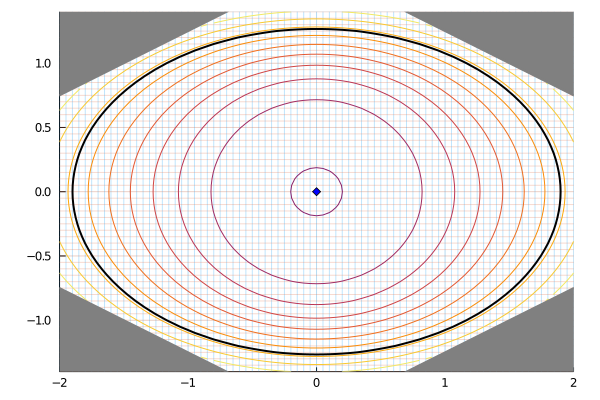

In [17]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, abs.(qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

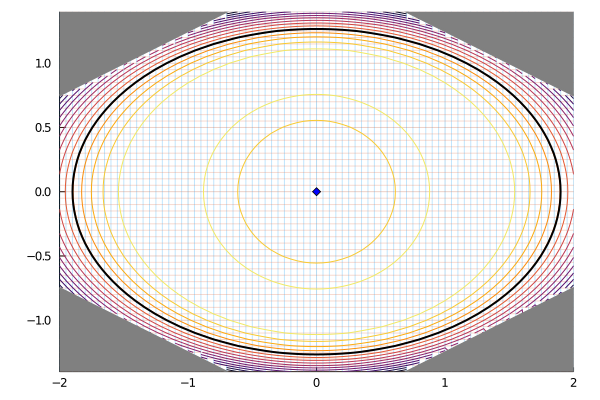

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, gsqs, aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, aspect_ratio=:equal, colorbar=false)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

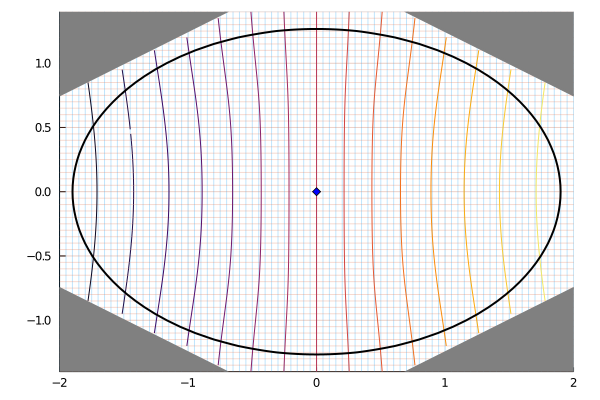

In [19]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, real((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

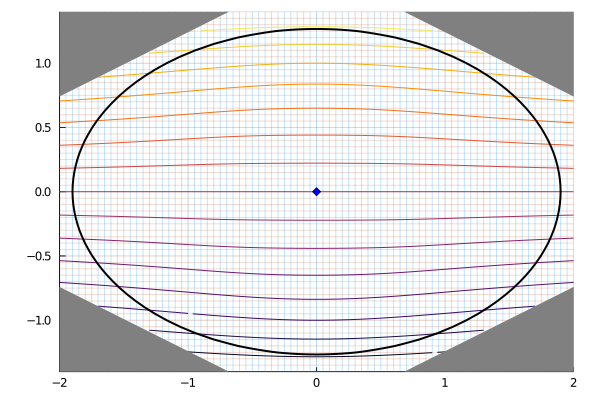

In [20]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, imag((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

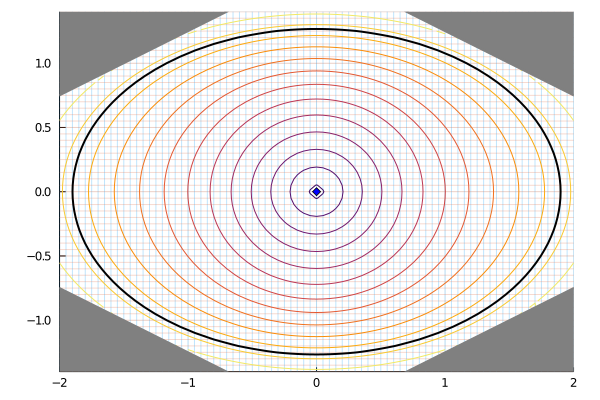

In [21]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
contour!(p, xs, ys, abs.((zs / σ) - sqrt(τ) * qs), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, gsqs, levels=[0.0], color=:black, lw=2)
#contour!(p, xs, ys, ks, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

mask_outside_region!(p, bounds, ys)

In [22]:
# Jacobian check
ws = RMSolver.RMWorkspace(problem)
RMSolver.G0i!(ws, z)
γsq = rbase ^ start
q = RMSolver.qstart(ws, γsq)
qv = [real(q); imag(q)];

In [23]:
# Analytical
Fv, Jv = zeros(2), zeros(2, 2)
RMSolver._qresidue!(Fv, Jv, ws, γsq, qv, Val(false))
Jv

2×2 Array{Float64,2}:
 -1.00034     -3.28865e-7
  3.28865e-7  -0.999663

In [24]:
# Numerical
δq = 0.001 * abs(q)
Fvδq = similar(Jv)
RMSolver._qresidue!((@view Fvδq[:, 1]), nothing, ws, γsq, qv + [δq; 0.0], Val(false))
RMSolver._qresidue!((@view Fvδq[:, 2]), nothing, ws, γsq, qv + [0.0; δq], Val(false))
(Fvδq .- Fv) / δq

2×2 Array{Float64,2}:
 -1.00034     -3.28864e-7
  3.28865e-7  -0.999663